## Naive Bayes

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
ds = pd.read_csv('ObesityDataSet_raw_and_data_sinthetic.csv')
ds.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [3]:
print(ds['NObeyesdad'].unique())

['Normal_Weight' 'Overweight_Level_I' 'Overweight_Level_II'
 'Obesity_Type_I' 'Insufficient_Weight' 'Obesity_Type_II'
 'Obesity_Type_III']


In [4]:
category = {
    'Insufficient_Weight': 0,
    'Normal_Weight': 1,
    'Overweight_Level_I': 2,
    'Overweight_Level_II': 3,
    'Obesity_Type_I': 4,
    'Obesity_Type_II': 5,
    'Obesity_Type_III': 6
}

In [5]:
ds['NObeyesdad'] = ds['NObeyesdad'].map(category).fillna(-1).astype(int)

In [6]:
for col in ds.select_dtypes(include=["object"]).columns:
    ds[col] = ds[col].astype("category").cat.codes

In [7]:
X = ds[["Age", "Height"]].values  
X = np.c_[np.ones(X.shape[0]), X]  
Y = ds["NObeyesdad"].values

In [8]:
def train_test_split(X, Y, test_size=0.2, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)
    indices = np.arange(X.shape[0])
    np.random.shuffle(indices)
    split_idx = int(X.shape[0] * (1 - test_size))
    X_train, X_test = X[indices[:split_idx]], X[indices[split_idx:]]
    Y_train, Y_test = Y[indices[:split_idx]], Y[indices[split_idx:]]
    return X_train, X_test, Y_train, Y_test

In [9]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [10]:
import numpy as np

class NaiveBayes:
    def __init__(self):
        self.classes = None
        self.class_priors = None
        self.means = None
        self.variances = None

    def fit(self, X, Y):
        self.classes = np.unique(Y)
        n_classes = len(self.classes)
        n_features = X.shape[1]
        
        self.means = np.zeros((n_classes, n_features))
        self.variances = np.zeros((n_classes, n_features))
        self.class_priors = np.zeros(n_classes)
        
        for i, c in enumerate(self.classes):
            X_c = X[Y == c]
            self.means[i, :] = X_c.mean(axis=0)
            self.variances[i, :] = X_c.var(axis=0)
            self.class_priors[i] = X_c.shape[0] / X.shape[0]
    
    def predict(self, X):
        y_pred = [self._predict(x) for x in X]
        return np.array(y_pred)
    
    def _predict(self, x):
        posteriors = []
        
        for i, c in enumerate(self.classes):
            prior = np.log(self.class_priors[i])
            posterior = np.sum(np.log(self._pdf(i, x)))
            posterior = prior + posterior
            posteriors.append(posterior)
        
        return self.classes[np.argmax(posteriors)]
    
    def _pdf(self, class_idx, x):
        mean = self.means[class_idx]
        var = self.variances[class_idx]
        numerator = np.exp(-((x - mean) ** 2) / (2 * var))
        denominator = np.sqrt(2 * np.pi * var)
        return numerator / denominator


In [18]:
nb = NaiveBayes(epsilon=1e-4)
nb.fit(X_train, Y_train)
Y_pred = nb.predict(X_test)

In [19]:
accuracy = np.mean(Y_pred == Y_test)
print(f"Model Accuracy: {accuracy:.2f}")

Model Accuracy: 0.55


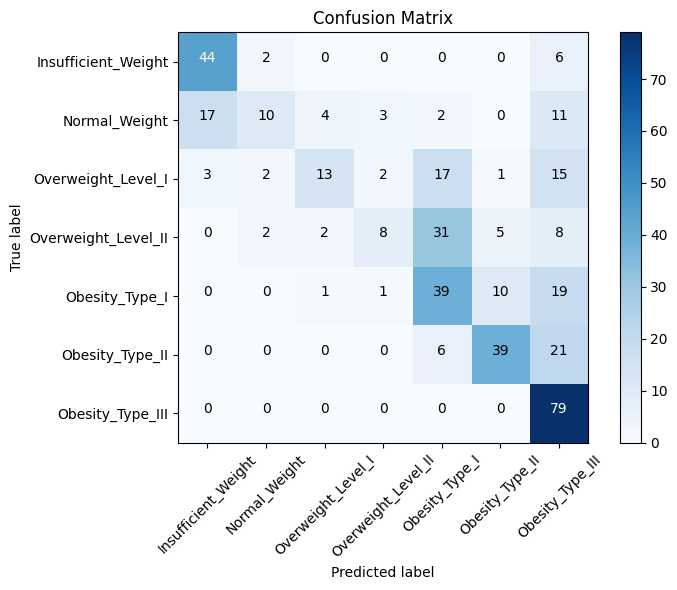

In [22]:
def plot_confusion_matrix(Y_true, Y_pred, classes):
    cm = np.zeros((len(classes), len(classes)))
    for t, p in zip(Y_true, Y_pred):
        cm[t, p] += 1

    
    plt.figure(figsize=(8, 6))
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    plt.title('Confusion Matrix')
    plt.colorbar()
    
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)
    
    thresh = cm.max() / 2.
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(j, i, f"{cm[i, j]:.0f}",
                     horizontalalignment="center",
                     color="white" if cm[i, j] > thresh else "black")
    
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.tight_layout()
    plt.show()

plot_confusion_matrix(Y_test, Y_pred, list(category.keys()))

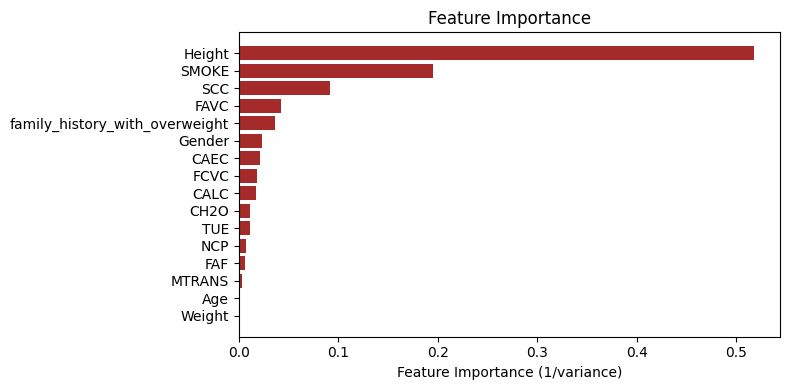

In [28]:
def plot_feature_importance(model, feature_names):
    avg_var = np.mean(model.variances, axis=0)
    importance = 1 / (avg_var + 1e-9)
    importance = importance / importance.sum()
    
    sorted_idx = np.argsort(importance)
    plt.figure(figsize=(8, 4))
    plt.barh(range(len(sorted_idx)), importance[sorted_idx], 
             align='center', color='brown')  # Changed color to brown
    plt.yticks(range(len(sorted_idx)), np.array(feature_names)[sorted_idx])
    plt.xlabel('Feature Importance (1/variance)')
    plt.title('Feature Importance')
    plt.tight_layout()
    plt.show()

plot_feature_importance(nb, ds.drop("NObeyesdad", axis=1).columns)